# Actividad 4: Análisis de emisiones de CO₂ (Our World in Data)

**Grupo G**

**Integrantes:** Alejandra Suesca Ortega, Maria Camila Hoyos, Yanin Mejia

**Curso:** (5932)

**Fuente de datos:** Our World in Data, https://ourworldindata.org/co2-emissions

## Objetivo

Analizar la evolución de las emisiones de CO₂, compararlas entre países y construir un modelo de regresión lineal para interpretar su relación con variables como el PIB y la población.+

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

url = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()


(56269, 79)


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 56269 entries, 0 to 56268
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    56269 non-null  str    
 1   year                                       56269 non-null  int64  
 2   iso_code                                   48306 non-null  str    
 3   population                                 44124 non-null  float64
 4   gdp                                        15367 non-null  float64
 5   cement_co2                                 38425 non-null  float64
 6   cement_co2_per_capita                      31816 non-null  float64
 7   co2                                        30219 non-null  float64
 8   co2_growth_abs                             28038 non-null  float64
 9   co2_growth_prct                            26839 non-null  float64
 10  co2_including_luc                

In [6]:
cols = ["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita"]
df[cols].isna().sum()

country               0
year                  0
iso_code           7963
population        12145
gdp               40902
co2               26050
co2_per_capita    29031
dtype: int64

In [7]:
df[cols].describe()

,year,population,gdp,co2,co2_per_capita
count,56269.000000,4.412400e+04,1.536700e+04,30219.000000,27238.000000
mean,1910.889388,5.785728e+07,3.277228e+11,416.443817,3.934807
std,72.084327,3.245160e+08,3.074832e+12,1980.807611,18.758294
min,1750.000000,2.100000e+01,4.998000e+07,0.000000,0.000000
25%,1862.000000,3.392082e+05,7.714758e+09,0.341000,0.169000
50%,1916.000000,2.285948e+06,2.701432e+10,4.668000,1.030500
75%,1971.000000,9.708646e+06,1.204248e+11,51.619500,4.315000
max,2025.000000,8.231613e+09,1.301126e+14,38995.105000,1062.532000


## Exploración inicial

El conjunto de datos de Our World in Data tiene 56269 filas y 79 columnas. Cada fila corresponde a un país o región en un año determinado, y los registros van desde 1750 hasta 2025.

Para el análisis se seleccionaron siete variables: country, year, iso_code, population, gdp, co2 y co2_per_capita.

Al revisar los valores nulos se observó que el PIB (gdp) es la variable con más datos faltantes (40902), seguida de co2_per_capita (29031), co2 (26050) y population (12145). Además, iso_code tiene 7963 nulos, que corresponden a regiones y agregados que no son países. Las variables country y year no tienen nulos. Esto ocurre sobre todo en los años más antiguos, porque en esa época no existían registros completos.

Con la función describe() se observó que el promedio de emisiones de CO₂ es de unos 416 millones de toneladas, pero la mediana es de solo 4,67. Esto indica que los datos están concentrados en pocos valores grandes. Los valores máximos (cerca de 38995) probablemente corresponden a agregados como el total mundial y no a un país. Por eso es necesario limpiar los datos antes de graficar y construir el modelo.

In [8]:
# 1. Quedarnos solo con las columnas necesarias
df_clean = df[cols].copy()

# 2. Eliminar agregados (World, Europe, etc.): no tienen código ISO
df_clean = df_clean[df_clean["iso_code"].notna()]

# 3. Años desde 1950 (hay más datos completos)
df_clean = df_clean[df_clean["year"] >= 1950]

# 4. Eliminar duplicados
df_clean = df_clean.drop_duplicates()

# 5. Eliminar filas con nulos en las variables del modelo
df_clean = df_clean.dropna(subset=["population", "gdp", "co2", "co2_per_capita"])

# 6. Verificación
print("Filas antes:", df.shape[0])
print("Filas después:", df_clean.shape[0])
print("Años:", df_clean["year"].min(), "a", df_clean["year"].max())
print("Países:", df_clean["country"].nunique())
df_clean.isna().sum()

Filas antes: 56269
Filas después: 11237
Años: 1950 a 2022
Países: 164


country           0
year              0
iso_code          0
population        0
gdp               0
co2               0
co2_per_capita    0
dtype: int64

## Limpieza de datos

1. Se seleccionaron solo las columnas necesarias para el análisis.
2. Se eliminaron los agregados (World, Europe, etc.) porque no son países. Estos registros no tienen código ISO y distorsionaban la media, porque sus valores son mucho mayores que los de cualquier país.
3. Se usaron los datos desde 1950 porque hay información más completa.
4. Se eliminaron los registros duplicados.
5. Se eliminaron las filas con valores nulos en las variables del modelo.

Después de la limpieza quedaron 11237 registros de 164 países, entre 1950 y 2022, sin valores nulos. La reducción desde 56269 filas se debe principalmente a que el PIB solo está disponible para una parte de los países y años.

## Visualización de los datos

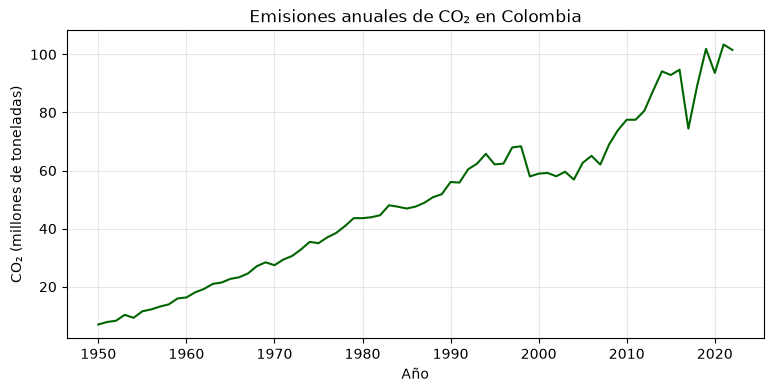

In [9]:
col = df_clean[df_clean["country"] == "Colombia"]
 
plt.figure(figsize=(9, 4))
plt.plot(col["year"], col["co2"], color="darkgreen")
plt.title("Emisiones anuales de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("CO₂ (millones de toneladas)")
plt.grid(alpha=0.3)
plt.show()


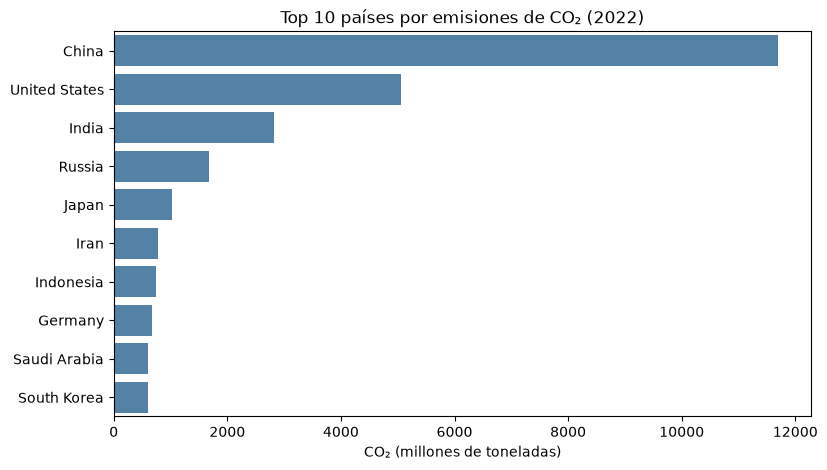

In [10]:
ultimo = df_clean["year"].max()
top10 = df_clean[df_clean["year"] == ultimo].nlargest(10, "co2")
 
plt.figure(figsize=(9, 5))
sns.barplot(data=top10, x="co2", y="country", color="steelblue")
plt.title(f"Top 10 países por emisiones de CO₂ ({ultimo})")
plt.xlabel("CO₂ (millones de toneladas)")
plt.ylabel("")
plt.show()


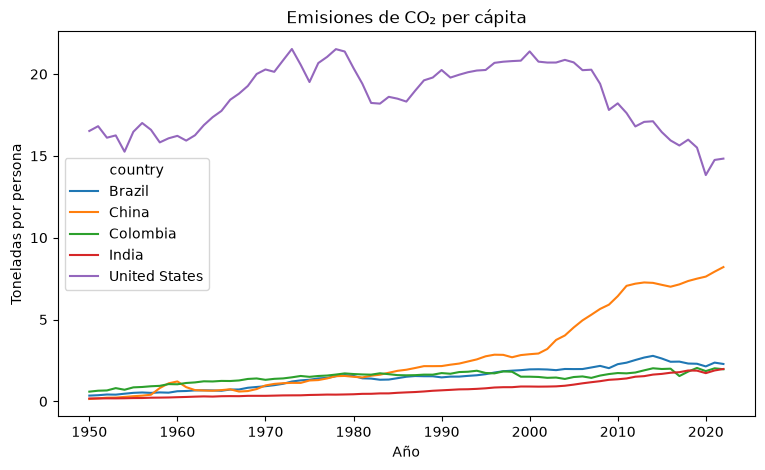

In [11]:
paises = ["Colombia", "United States", "China", "Brazil", "India"]
comp = df_clean[df_clean["country"].isin(paises)]
 
plt.figure(figsize=(9, 5))
sns.lineplot(data=comp, x="year", y="co2_per_capita", hue="country")
plt.title("Emisiones de CO₂ per cápita")
plt.xlabel("Año")
plt.ylabel("Toneladas por persona")
plt.show()


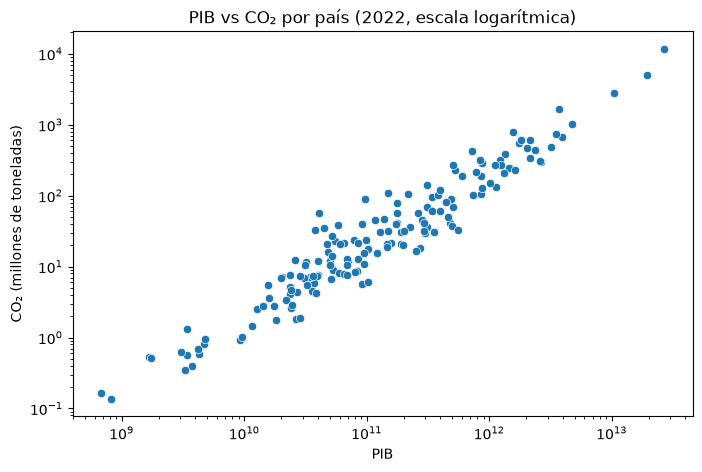

In [12]:
datos_ultimo = df_clean[df_clean["year"] == ultimo]
 
plt.figure(figsize=(8, 5))
sns.scatterplot(data=datos_ultimo, x="gdp", y="co2")
plt.xscale("log")
plt.yscale("log")
plt.title(f"PIB vs CO₂ por país ({ultimo}, escala logarítmica)")
plt.xlabel("PIB")
plt.ylabel("CO₂ (millones de toneladas)")
plt.show()


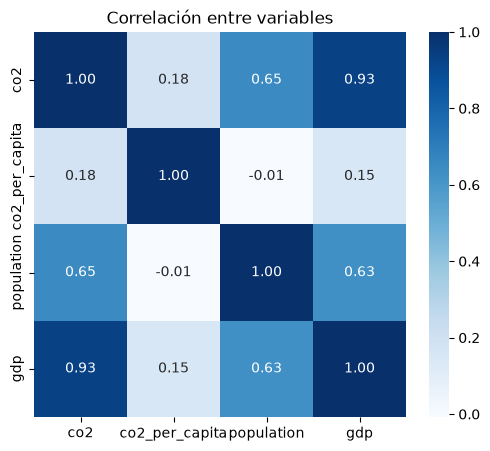

In [13]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_clean[["co2", "co2_per_capita", "population", "gdp"]].corr(),
            annot=True, cmap="Blues", fmt=".2f")
plt.title("Correlación entre variables")
plt.show()


## Interpretación de los gráficos
 
**Gráfico 1. Emisiones de CO₂ en Colombia.** Las emisiones de Colombia muestran una tendencia creciente desde 1950. Este aumento acompaña el crecimiento de la población, de la economía y del consumo de energía del país.
 
**Gráfico 2. Los 10 países que más emiten.** Las emisiones están concentradas en pocos países. China y Estados Unidos encabezan la lista, seguidos de India, con una diferencia grande frente a los demás. Esto muestra la desigualdad en la contribución de cada país al total mundial.
 
**Gráfico 3. Emisiones per cápita.** Al comparar por persona, el orden cambia. Estados Unidos tiene el valor más alto de los cinco países, seguido de China, mientras que Colombia, Brasil e India quedan por debajo. Un país con muchas emisiones totales, como India, no necesariamente emite mucho por habitante.
 
**Gráfico 4. PIB frente a CO₂.** Se observa una relación positiva: los países con mayor PIB tienden a emitir más CO₂. La relación no es perfecta, porque países con economías parecidas pueden tener emisiones distintas según su matriz energética.
 
**Gráfico 5. Mapa de correlaciones.** El CO₂ total tiene una correlación fuerte y positiva con el PIB y con la población. El CO₂ per cápita se relaciona mucho menos con la población, lo que indica que el tamaño del país no explica por sí solo cuánto emite cada persona.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

## Modelos de regresión lineal


Pendiente: 1.23 Mt por año
Intercepto: -2393.71
R²: 0.96
Predicción para 2030: 103.0 Mt


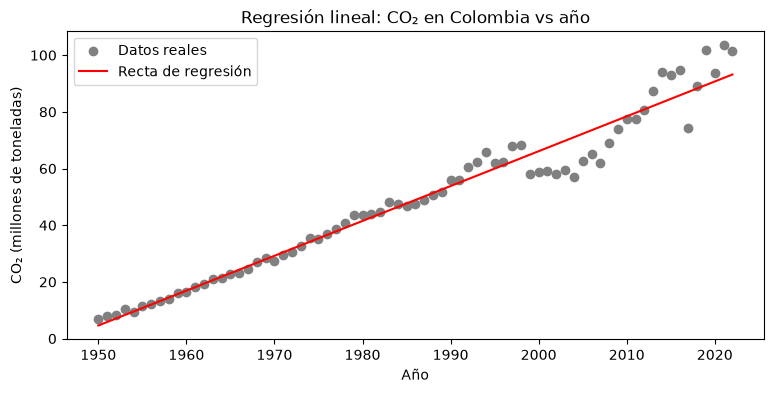

In [15]:
col = df_clean[df_clean["country"] == "Colombia"]
 
X = col[["year"]]
y = col["co2"]
 
modelo_a = LinearRegression()
modelo_a.fit(X, y)
pred_a = modelo_a.predict(X)
pred_2030 = float(modelo_a.predict(pd.DataFrame({"year": [2030]}))[0])
 
print(f"Pendiente: {float(modelo_a.coef_[0]):.2f} Mt por año")
print(f"Intercepto: {float(modelo_a.intercept_):.2f}")
print(f"R²: {r2_score(y, pred_a):.2f}")
print(f"Predicción para 2030: {pred_2030:.1f} Mt")
 
plt.figure(figsize=(9, 4))
plt.scatter(X, y, label="Datos reales", color="gray")
plt.plot(X, pred_a, color="red", label="Recta de regresión")
plt.title("Regresión lineal: CO₂ en Colombia vs año")
plt.xlabel("Año")
plt.ylabel("CO₂ (millones de toneladas)")
plt.legend()
plt.show()


Coeficiente PIB: 4.130e-10
Coeficiente población: 5.385e-07
R² (prueba): 0.86
RMSE: 189.65 Mt


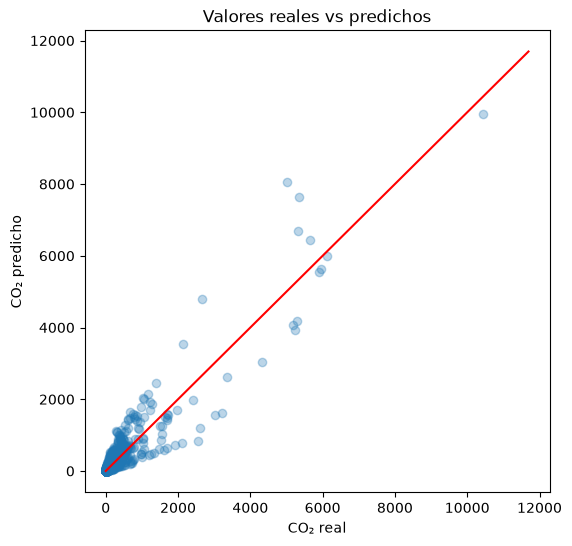

In [16]:
X = df_clean[["gdp", "population"]]
y = df_clean["co2"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
 
modelo_b = LinearRegression()
modelo_b.fit(X_train, y_train)
pred_b = modelo_b.predict(X_test)
 
r2_b = r2_score(y_test, pred_b)
rmse_b = float(np.sqrt(mean_squared_error(y_test, pred_b)))
 
print(f"Coeficiente PIB: {float(modelo_b.coef_[0]):.3e}")
print(f"Coeficiente población: {float(modelo_b.coef_[1]):.3e}")
print(f"R² (prueba): {r2_b:.2f}")
print(f"RMSE: {rmse_b:.2f} Mt")
 
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_b, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.title("Valores reales vs predichos")
plt.xlabel("CO₂ real")
plt.ylabel("CO₂ predicho")
plt.show()


In [17]:
resumen = pd.DataFrame({
    "Resultado": ["Modelo A: pendiente (Mt/año)", "Modelo A: R²",
                  "Modelo A: predicción 2030 (Mt)", "Modelo B: R² (prueba)",
                  "Modelo B: RMSE (Mt)"],
    "Valor": [f"{float(modelo_a.coef_[0]):.2f}", f"{r2_score(col['co2'], pred_a):.2f}",
              f"{pred_2030:.1f}", f"{r2_b:.2f}", f"{rmse_b:.2f}"]
})
resumen


,Resultado,Valor
0,Modelo A: pendiente (Mt/año),1.23
1,Modelo A: R²,0.96
2,Modelo A: predicción 2030 (Mt),103.0
3,Modelo B: R² (prueba),0.86
4,Modelo B: RMSE (Mt),189.65


## Resultados e interpretación de los modelos
 
**Modelo A. Regresión simple (Colombia, año frente a CO₂).** La pendiente fue de ___ millones de toneladas por año, es decir, que en promedio las emisiones de Colombia aumentan esa cantidad cada año. El R² fue de ___, lo que significa que el año explica aproximadamente el ___ % de la variación de las emisiones. La predicción para 2030 fue de ___ millones de toneladas, un valor que supone que la tendencia se mantiene y no considera cambios en políticas ni en la economía.
 
**Modelo B. Regresión múltiple (PIB y población frente a CO₂).** El R² en los datos de prueba fue de ___, lo que significa que el PIB y la población explican cerca del ___ % de la variación de las emisiones entre países. El RMSE fue de ___ millones de toneladas, es decir, que en promedio cada predicción se equivoca en esa cantidad. Ese error es pequeño para países muy grandes, como China o Estados Unidos, pero es enorme frente a la mediana de emisiones, que es de unos 4,7 millones de toneladas. Por eso un R² alto no significa que el modelo sea preciso para todos los países.
 
**Comparación y limitaciones.** El Modelo ___ se ajustó mejor a los datos. Ambos modelos tienen limitaciones: la relación entre las variables no es perfectamente lineal, unos pocos países con emisiones enormes dominan el resultado, y hay otras variables que influyen, como la matriz energética y las políticas ambientales.
